In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings("ignore")
%matplotlib inline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder

In [2]:
df = pd.read_csv("Titanic-Dataset.csv")      # Titanic (Kaggle train.csv) - keep it in the same folder as this notebook
print("Rows:", df.shape[0], " Columns:", df.shape[1])
df.head()
df.info()

Rows: 891  Columns: 12
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [3]:
missing = pd.DataFrame({"Missing": df.isnull().sum(), 
                        "Percent": (df.isnull().mean()*100).round(2)})
missing[missing["Missing"] > 0]

,Missing,Percent
Age,177,19.87
Cabin,687,77.10
Embarked,2,0.22


In [4]:
df_clean = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"], errors="ignore").copy()
numeric_cols = df_clean.select_dtypes(include=np.number).columns
categorical_cols = df_clean.select_dtypes(exclude=np.number).columns

for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in categorical_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print("Missing values remaining:",df_clean.isnull().sum().sum())
print("Categorical:", categorical_cols.tolist())

Missing values remaining: 0
Categorical: ['Sex', 'Embarked']


In [5]:
for col in categorical_cols:
    print(col, df_clean[col].unique())

df_encoded = pd.get_dummies(df_clean, columns=categorical_cols, drop_first=True)
print(df_encoded.shape)
print(df_encoded.head())

demo_col = "Sex"
codes = LabelEncoder().fit_transform(df_clean[demo_col].astype(str))
print(pd.DataFrame({demo_col: df_clean[demo_col], "Encoded": codes}).head())

Sex ['male' 'female']
Embarked ['S' 'C' 'Q']
(891, 9)
   Survived  Pclass   Age  SibSp  Parch     Fare  Sex_male  Embarked_Q  \
0         0       3  22.0      1      0   7.2500      True       False   
1         1       1  38.0      1      0  71.2833     False       False   
2         1       3  26.0      0      0   7.9250     False       False   
3         1       1  35.0      1      0  53.1000     False       False   
4         0       3  35.0      0      0   8.0500      True       False   

   Embarked_S  
0        True  
1       False  
2        True  
3        True  
4        True  
      Sex  Encoded
0    male        1
1  female        0
2  female        0
3  female        0
4    male        1


In [6]:
#scale_cols = ["Age", "SibSp", "Parch", "Fare"]
std_df = pd.DataFrame(StandardScaler().fit_transform(df_clean[numeric_cols]), columns=numeric_cols)
mm_df = pd.DataFrame(MinMaxScaler().fit_transform(df_clean[numeric_cols]), columns=numeric_cols)

print(std_df.agg(["mean", "std"]).round(2))
print(mm_df.agg(["min", "max"]).round(2))

      Survived  Pclass  Age  SibSp  Parch  Fare
mean       0.0    -0.0  0.0    0.0    0.0   0.0
std        1.0     1.0  1.0    1.0    1.0   1.0
     Survived  Pclass  Age  SibSp  Parch  Fare
min       0.0     0.0  0.0    0.0    0.0   0.0
max       1.0     1.0  1.0    1.0    1.0   1.0


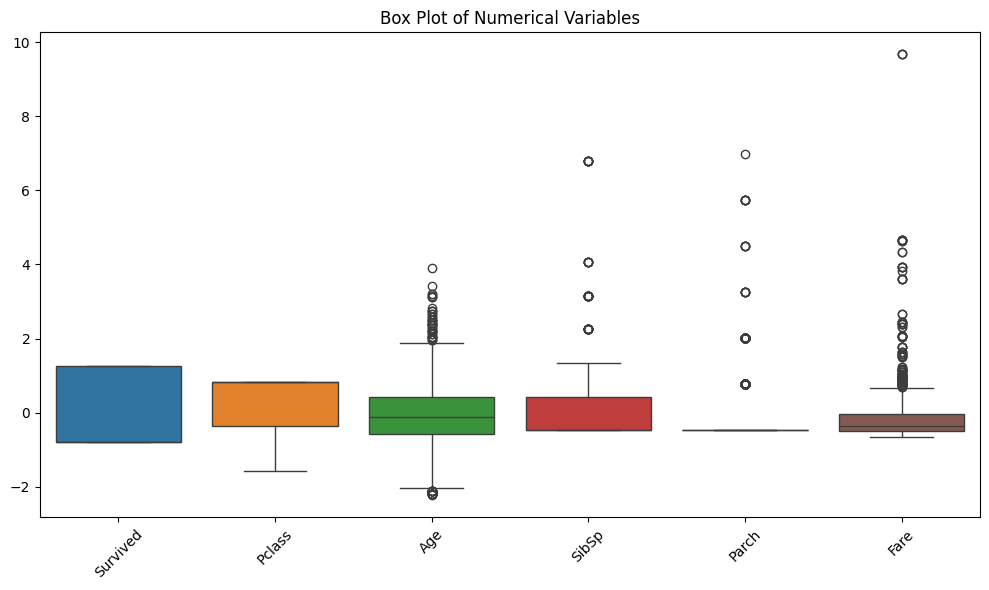

     Column       Q1    Q3      IQR   Lower    Upper  Outliers
0  Survived   0.0000   1.0   1.0000  -1.500   2.5000         0
1    Pclass   2.0000   3.0   1.0000   0.500   4.5000         0
2       Age  22.0000  35.0  13.0000   2.500  54.5000        66
3     SibSp   0.0000   1.0   1.0000  -1.500   2.5000        46
4     Parch   0.0000   0.0   0.0000   0.000   0.0000       213
5      Fare   7.9104  31.0  23.0896 -26.724  65.6344       116


In [7]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=std_df)
plt.title("Box Plot of Numerical Variables")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

rows = []
for col in numeric_cols:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df_clean[col] < lo) | (df_clean[col] > hi)).sum()
    rows.append([col, q1, q3, iqr, lo, hi, n])

iqr_table = pd.DataFrame(rows, columns=["Column", "Q1", "Q3", "IQR", "Lower", "Upper", "Outliers"])
print(iqr_table)

In [10]:
outlier_col = "Fare"
lo, hi = iqr_table.set_index("Column").loc[outlier_col, ["Lower", "Upper"]]
df_final = df_clean[df_clean[outlier_col].between(lo, hi)].copy()
print(len(df_clean), len(df_final))

891 775


In [11]:
df_clean.to_csv("preprocessed_titanic.csv", index=False)
print("Saved preprocessed_titanic.csv")

Saved preprocessed_titanic.csv
